In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("data/linie/2026-11-02_linie_48.csv", dtype=str)
print("Zeilen:", len(df))
print("Fahrten:", df["FAHRT_BEZEICHNER"].nunique())
df["HALTESTELLEN_NAME"].value_counts()

Zeilen: 2470
Fahrten: 172


HALTESTELLEN_NAME
Basel Bachgraben          172
Wänglismatten             172
Kreuzstrasse              172
Im Brühl                  172
Hagmattstrasse            172
Gartenstrasse             172
Ziegelei                  172
Kirche                    172
Wanderstrasse             172
Schützenhaus              172
Bahnhof SBB               172
General Guisan-Strasse     87
Wielandplatz               85
St.Galler-Ring             85
Rigistrasse                85
Bahnhof St.Johann          59
Felix Platter-Spital       59
Thomaskirche               59
Belforterstrasse           59
Name: count, dtype: int64

In [2]:
# Nur Halte, an denen wirklich gemessen wurde (REAL)
gemessen = df[df["AB_PROGNOSE_STATUS"] == "REAL"].copy()

gemessen["geplant"] = pd.to_datetime(gemessen["ABFAHRTSZEIT"], format="mixed", dayfirst=True)
gemessen["tatsaechlich"] = pd.to_datetime(gemessen["AB_PROGNOSE"], format="mixed", dayfirst=True)
gemessen["verspaetung_min"] = (gemessen["tatsaechlich"] - gemessen["geplant"]).dt.total_seconds() / 60

print("Gemessene Abfahrten:", len(gemessen))
gemessen["verspaetung_min"].describe().round(2)

Gemessene Abfahrten: 2289


count    2289.00
mean        1.76
std         2.18
min       -12.20
25%         0.55
50%         1.13
75%         2.23
max        14.52
Name: verspaetung_min, dtype: float64

Pünktlich (weniger als 3 Min. Verspätung): 84.0 %


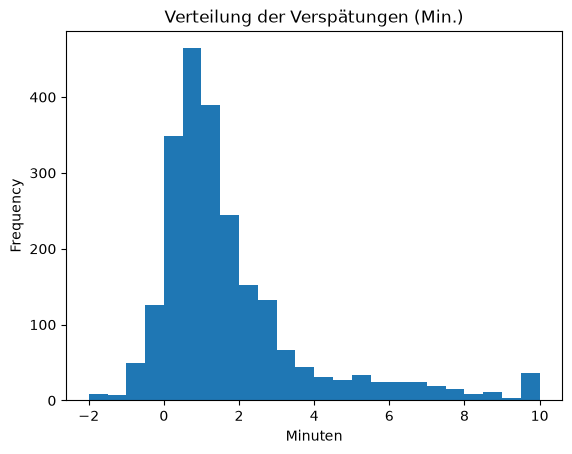

In [3]:
puenktlich = (gemessen["verspaetung_min"] < 3).mean() * 100
print(f"Pünktlich (weniger als 3 Min. Verspätung): {puenktlich:.1f} %")

gemessen["verspaetung_min"].clip(-2, 10).plot.hist(bins=24, title="Verteilung der Verspätungen (Min.)")
plt.xlabel("Minuten")
plt.show()

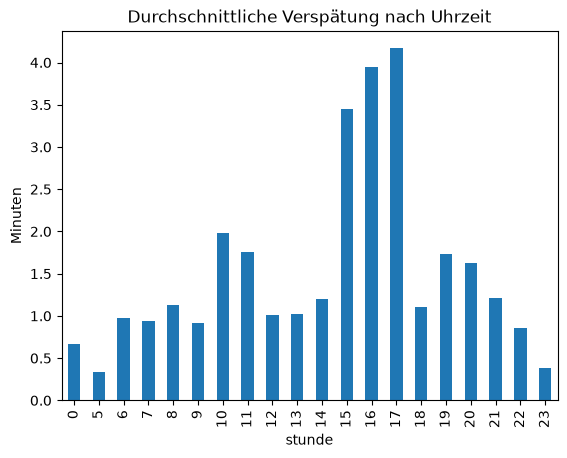

In [4]:
gemessen["stunde"] = gemessen["geplant"].dt.hour
gemessen.groupby("stunde")["verspaetung_min"].mean().plot.bar(
    title="Durchschnittliche Verspätung nach Uhrzeit"
)
plt.ylabel("Minuten")
plt.show()

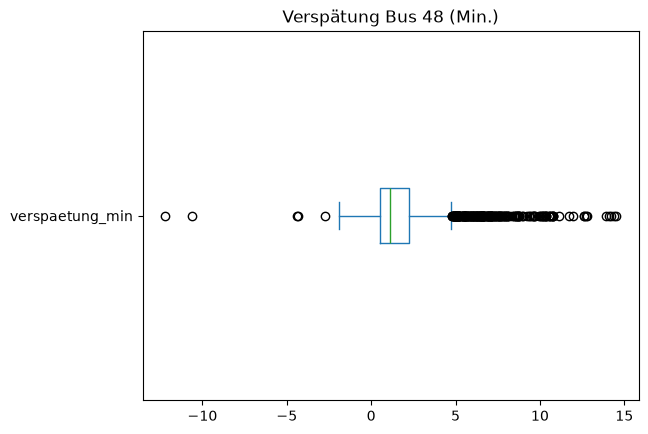

In [5]:
gemessen["verspaetung_min"].plot.box(vert=False, title="Verspätung Bus 48 (Min.)")
plt.show()

In [10]:
from pathlib import Path

dateien = sorted(Path("data/linie").glob("*_linie_48.csv"))
alle = pd.concat([pd.read_csv(p, dtype=str) for p in dateien])

gemessen = alle[alle["AB_PROGNOSE_STATUS"] == "REAL"].copy()
gemessen["geplant"] = pd.to_datetime(gemessen["ABFAHRTSZEIT"], format="mixed", dayfirst=True)
gemessen["tatsaechlich"] = pd.to_datetime(gemessen["AB_PROGNOSE"], format="mixed", dayfirst=True)
gemessen["verspaetung_min"] = (gemessen["tatsaechlich"] - gemessen["geplant"]).dt.total_seconds() / 60

# Messfehler weglassen (mehr als 2 Min. zu früh ist für einen Bus unrealistisch)
gemessen = gemessen[gemessen["verspaetung_min"] >= -2]

gemessen["tag"] = pd.to_datetime(gemessen["BETRIEBSTAG"], format="%d.%m.%Y").dt.date
gemessen["stunde"] = gemessen["geplant"].dt.hour

print("Tage:", len(dateien), "· gemessene Abfahrten:", len(gemessen))

Tage: 6 · gemessene Abfahrten: 13652


In [11]:
pro_tag = gemessen.groupby("tag")["verspaetung_min"].agg(
    durchschnitt="mean",
    puenktlich=lambda v: (v < 3).mean() * 100,
).round(1)
pro_tag

,durchschnitt,puenktlich
tag,,
2026-10-26,1.5,85.5
2026-10-27,1.8,83.9
2026-10-28,1.7,83.8
2026-10-29,3.7,74.5
2026-10-30,1.4,87.0
2026-11-02,1.8,84.0


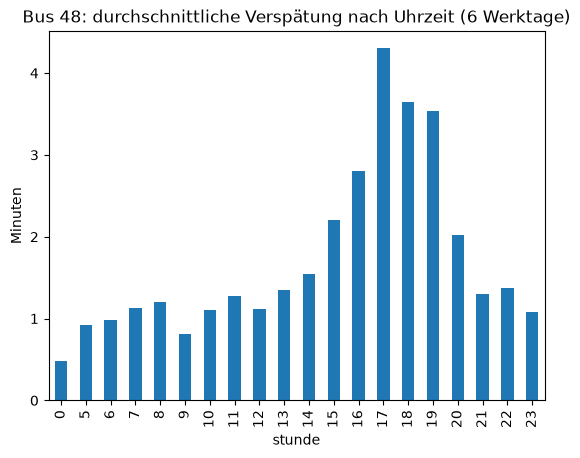

In [12]:
gemessen.groupby("stunde")["verspaetung_min"].mean().plot.bar(
    title="Bus 48: durchschnittliche Verspätung nach Uhrzeit (6 Werktage)"
)
plt.ylabel("Minuten")
plt.show()

In [13]:
ziegelei = gemessen[gemessen["HALTESTELLEN_NAME"] == "Ziegelei"]
ziegelei.groupby("stunde")["verspaetung_min"].mean().round(1)

stunde
0     1.1
5     1.0
6     1.1
7     1.2
8     1.1
9     0.9
10    1.1
11    1.3
12    1.1
13    1.4
14    1.7
15    2.5
16    3.0
17    4.6
18    3.7
19    3.8
20    2.3
21    1.4
22    1.9
23    1.8
Name: verspaetung_min, dtype: float64